# Constructing backtest paths from combinatorial splits

This native Julia companion preserves the public data, six time groups, two test groups, one-percent embargo, five paths and scaled C=1 logistic model. Saved public seed-15 bootstrap draws and member seeds supply the bagging randomness; fitting and path assembly execute in Julia. Standardization is unweighted within each full training split, and bagged logistic fits use bootstrap multiplicities, matching the public estimator. Adaptive boundaries retain the original full-sample volatility quantiles and subsplit rule. Observation positions are one-based, and outputs are saved under `outputs/julia`.

The number of distinct train-test arrangements is given by:

$$
S(N,k)=\binom{N}{k}=\frac{N!}{k!(N-k)!}.
$$

Here, $N$ is the number of time-ordered groups, $k$ is the number of groups placed in each test set, $S(N,k)$ is the number of distinct arrangements, and $!$ denotes the factorial.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("17_combinatorial_purged_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "design"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter15-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

using Combinatorics: combinations
using RiskLabAI.Validation: CombinatorialPurgedCV,BaggedCombinatorialPurgedCV,AdaptiveCombinatorialPurgedCV,backtest_paths,get_n_splits
@assert count_observations==2951 && size(public_x)==(2951,6)
external_feature = public_x[:,3]
state_colors = [palette.grid,palette.cyan,palette.rose,palette.amber]
path_colors = [palette.background,palette.cyan,palette.amber,palette.green,palette.rose,violet]

function categorical_legend!(figure,colors,labels)
    for (color,label) in zip(colors,labels)
        plot!(figure,[NaN],[NaN];color,marker=:rect,linewidth=3,label)
    end
    plot!(figure;colorbar=false,legend=:outerright)
    return figure
end

function save_matrix(values,name)
    frame = DataFrame(values,:auto)
    insertcols!(frame,1,:row=>collect(1:size(values,1)))
    save_data(frame,paths,name)
    return nothing
end

function path_scores(method,predictions)
    rows = NamedTuple[]
    for number in sort(collect(keys(predictions)))
        values = predictions[number]
        push!(rows,(method=method,path=number,predictions=length(values),correct=sum(values.==public_y),accuracy=mean(values.==public_y),positive_share=mean(values.==1)))
    end
    result = DataFrame(rows)
    rename!(result,["Method","Path","Predictions","Correct predictions","Accuracy","Positive prediction share"])
    return result
end

function fit_paths(validator,name;sample_indices=nothing,feature_indices=nothing,estimator_seeds=nothing)
    members = validator isa BaggedCombinatorialPurgedCV ? validator.n_estimators : 1
    records,models = NamedTuple[],BookEstimators.LogisticModel[]
    data_positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    @assert length(data_positions)==count_observations
    fit_callback = function(seed,x,y,weights)
        fit_number = length(records)+1
        split,member = cld(fit_number,members),mod1(fit_number,members)
        model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,standardize=true,class_weight=nothing,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,model)
        fields = Dict{Symbol,Any}(:split=>split,:member=>member,:seed=>seed,:training_observations=>length(y),:weight_sum=>sum(weights),:positive_weights=>count(>(0),weights),:intercept=>model.intercept,:objective=>model.objective,:gradient_norm=>model.gradient_norm,:iterations=>model.iterations,:converged=>model.converged)
        for index in 1:6
            fields[Symbol("b",index)] = model.coefficients[index]
            fields[Symbol("center",index)] = model.scaler.center[index]
            fields[Symbol("scale",index)] = model.scaler.scale[index]
        end
        keys_order = [:split,:member,:seed,:training_observations,:weight_sum,:positive_weights,:intercept,:objective,:gradient_norm,:iterations,:converged]
        append!(keys_order,[Symbol(prefix,index) for prefix in ["b","center","scale"] for index in 1:6])
        push!(records,NamedTuple{Tuple(keys_order)}(Tuple(fields[key] for key in keys_order)))
        save_data(DataFrame(position=[data_positions[Tuple(row)] for row in eachrow(x)],weight=weights),paths,name*"_fit_"*string(fit_number)*"_weights")
        return model
    end
    predictions = if members==1
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=identity,fit_estimator=fit_callback,predict=BookEstimators.predict)
    else
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=(_,seed)->seed,fit_estimator=fit_callback,predict=BookEstimators.predict,predict_proba=BookEstimators.predict_proba,estimator_classes=model->model.classes,fit_sample_weights=true,sample_indices,feature_indices,estimator_seeds)
    end
    save_data(DataFrame(records),paths,name*"_fits")
    evidence = DataFrame(position=collect(1:count_observations),date=dates,actual=public_y)
    for number in sort(collect(keys(predictions)))
        evidence[!,"path_"*string(number)] = predictions[number]
    end
    save_data(evidence,paths,name*"_predictions")
    save_splits(name,cv_split(validator))
    return predictions,models
end


fit_paths (generic function with 1 method)

## Public Data

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Market","Bar length","Label horizon","Analysis start","Analysis end","Observations"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Bitcoin to Tether spot market","15 minutes","2 hours",format_time(first(dates)),format_time(last(dates)),"2,951"])
table(data_provenance,"data_provenance","Fixed public observations used in Chapter 15.")


9×2 DataFrame
 Row │ Field           Value
     │ String          String
─────┼───────────────────────────────────────────────────
   1 │ Archive         BTCUSDT-1m-2021-01.zip
   2 │ Provider        Binance Data Vision
   3 │ Market          Bitcoin to Tether spot market
   4 │ Bar length      15 minutes
   5 │ Label horizon   2 hours
   6 │ Analysis start  2021-01-01 04:15:00
   7 │ Analysis end    2021-01-31 21:45:00
   8 │ Observations    2,951

## All Test Combinations

Row,Groups,Test groups,Training groups,Distinct splits,Test appearances per group,Backtest paths,Nominal training share
,Int64,Int64,Int64,Int64,Int64,Int64,Float64
1,4,1,3,4,1,1,0.75
2,4,2,2,6,3,3,0.5
3,5,1,4,5,1,1,0.8
4,5,2,3,10,4,4,0.6
5,6,1,5,6,1,1,0.833333
6,6,2,4,15,5,5,0.666667
7,6,3,3,20,10,10,0.5
8,7,1,6,7,1,1,0.857143
9,7,2,5,21,6,6,0.714286


Row,Group,Test appearances,Path segments
,Int64,Int64,Int64
1,1,5,5
2,2,5,5
3,3,5,5
4,4,5,5
5,5,5,5
6,6,5,5


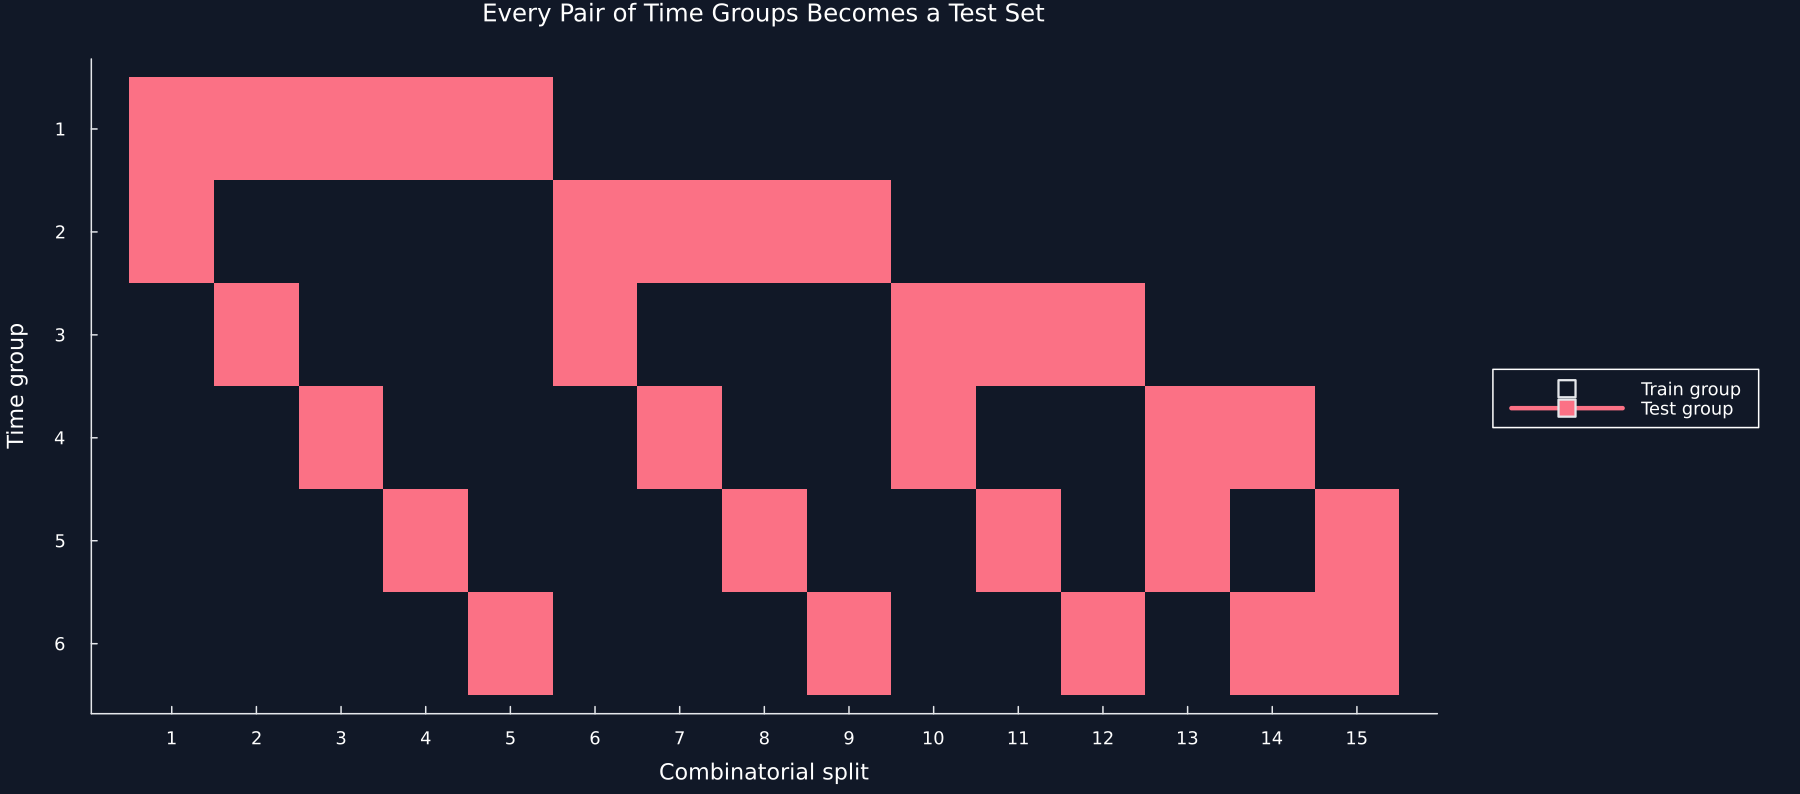

In [3]:
n_groups,n_test_groups = 6,2
combinations_list = collect(combinations(1:n_groups,n_test_groups))
incidence = zeros(Int,n_groups,length(combinations_list))
for (split,test_groups) in enumerate(combinations_list)
    incidence[test_groups,split] .= 1
end
locations = RiskLabAI.Validation._path_locations(n_groups,combinations_list)
count_records = NamedTuple[]
for groups in 4:10, tested in 1:fld(groups,2)
    push!(count_records,(groups=groups,test=tested,train=groups-tested,splits=binomial(groups,tested),appearances=binomial(groups-1,tested-1),paths=div(tested*binomial(groups,tested),groups),share=1-tested/groups))
end
combinatorial_counts = DataFrame(count_records)
rename!(combinatorial_counts,["Groups","Test groups","Training groups","Distinct splits","Test appearances per group","Backtest paths","Nominal training share"])
table(combinatorial_counts,"combinatorial_counts","Split counts, path counts, and nominal training shares for selected combinatorial designs.")
group_test_coverage = DataFrame("Group"=>collect(1:n_groups),"Test appearances"=>vec(sum(incidence;dims=2)),"Path segments"=>[sum(count(coordinate->coordinate[1]==group,path) for path in values(locations)) for group in 1:n_groups])
table(group_test_coverage,"group_test_coverage","Uniform test use of each time group for the six-group, two-test-group design.")
save_matrix(incidence,"combinatorial_incidence")
figure = heatmap(1:15,1:6,incidence;color=cgrad([palette.background,palette.rose],categorical=true),clims=(-.5,1.5),colorbar=false,yflip=true,xticks=1:15,yticks=1:6,xlabel="Combinatorial split",ylabel="Time group",title="Every Pair of Time Groups Becomes a Test Set",size=(1200,530),grid=false)
categorical_legend!(figure,[palette.background,palette.rose],["Train group","Test group"])
save_figure(figure,paths,"combinatorial_incidence")


Each group appears equally often in testing, and the number of full paths is:

$$
r(N,k)=\binom{N-1}{k-1},
\qquad
\varphi(N,k)=\frac{k}{N}\binom{N}{k}=r(N,k).
$$

Here, $r(N,k)$ is the number of test appearances of each group, $\varphi(N,k)$ is the number of complete backtest paths, and the other symbols retain their earlier meanings. Each complete path uses every group once.

## Assigning Tested Groups to Paths

Row,Path,Time group,Split,Full test combination
,Int64,Int64,Int64,String
1,1,1,1,1 and 2
2,1,2,1,1 and 2
3,1,3,2,1 and 3
4,1,4,3,1 and 4
5,1,5,4,1 and 5
6,1,6,5,1 and 6
7,2,1,2,1 and 3
8,2,2,6,2 and 3
9,2,3,6,2 and 3


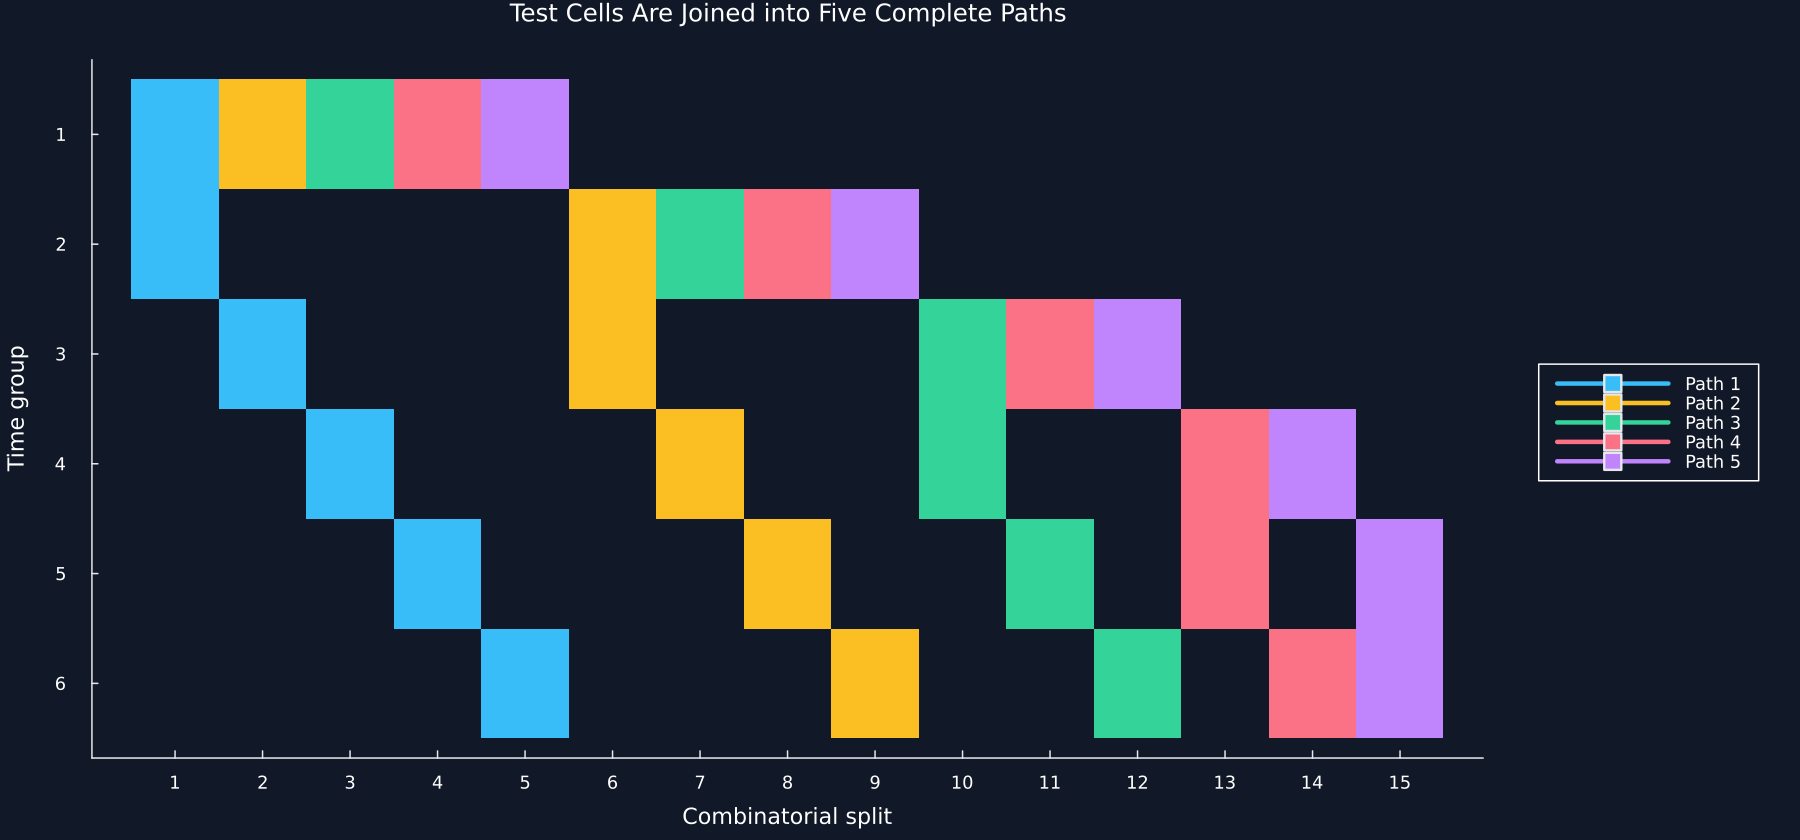

In [4]:
assignment = zeros(Int,size(incidence))
assignment_records = NamedTuple[]
for path in sort(collect(keys(locations))), (group,split) in locations[path]
    assignment[group,split] = path
    push!(assignment_records,(path=path,group=group,split=split,combination=join(combinations_list[split]," and ")))
end
path_assignment = DataFrame(assignment_records)
rename!(path_assignment,["Path","Time group","Split","Full test combination"])
sort!(path_assignment,["Path","Time group"])
table(path_assignment,"path_assignment","Assignment of tested time groups to five complete paths.")
save_matrix(assignment,"path_assignment")
figure = heatmap(1:15,1:6,assignment;color=cgrad(path_colors,categorical=true),clims=(-.5,5.5),colorbar=false,yflip=true,xticks=1:15,yticks=1:6,xlabel="Combinatorial split",ylabel="Time group",title="Test Cells Are Joined into Five Complete Paths",size=(1200,560),grid=false)
categorical_legend!(figure,path_colors[2:end],["Path "*string(index) for index in 1:5])
save_figure(figure,paths,"path_assignment")


The nominal share available for fitting in each split is:

$$
\theta(N,k)=1-\frac{k}{N}.
$$

Here, $\theta(N,k)$ is the training share before purging and embargo, $N$ is the total number of groups, and $k$ is the number of tested groups. Increasing $k$ creates more paths but leaves less data for fitting.

## Relating training share to the number of paths

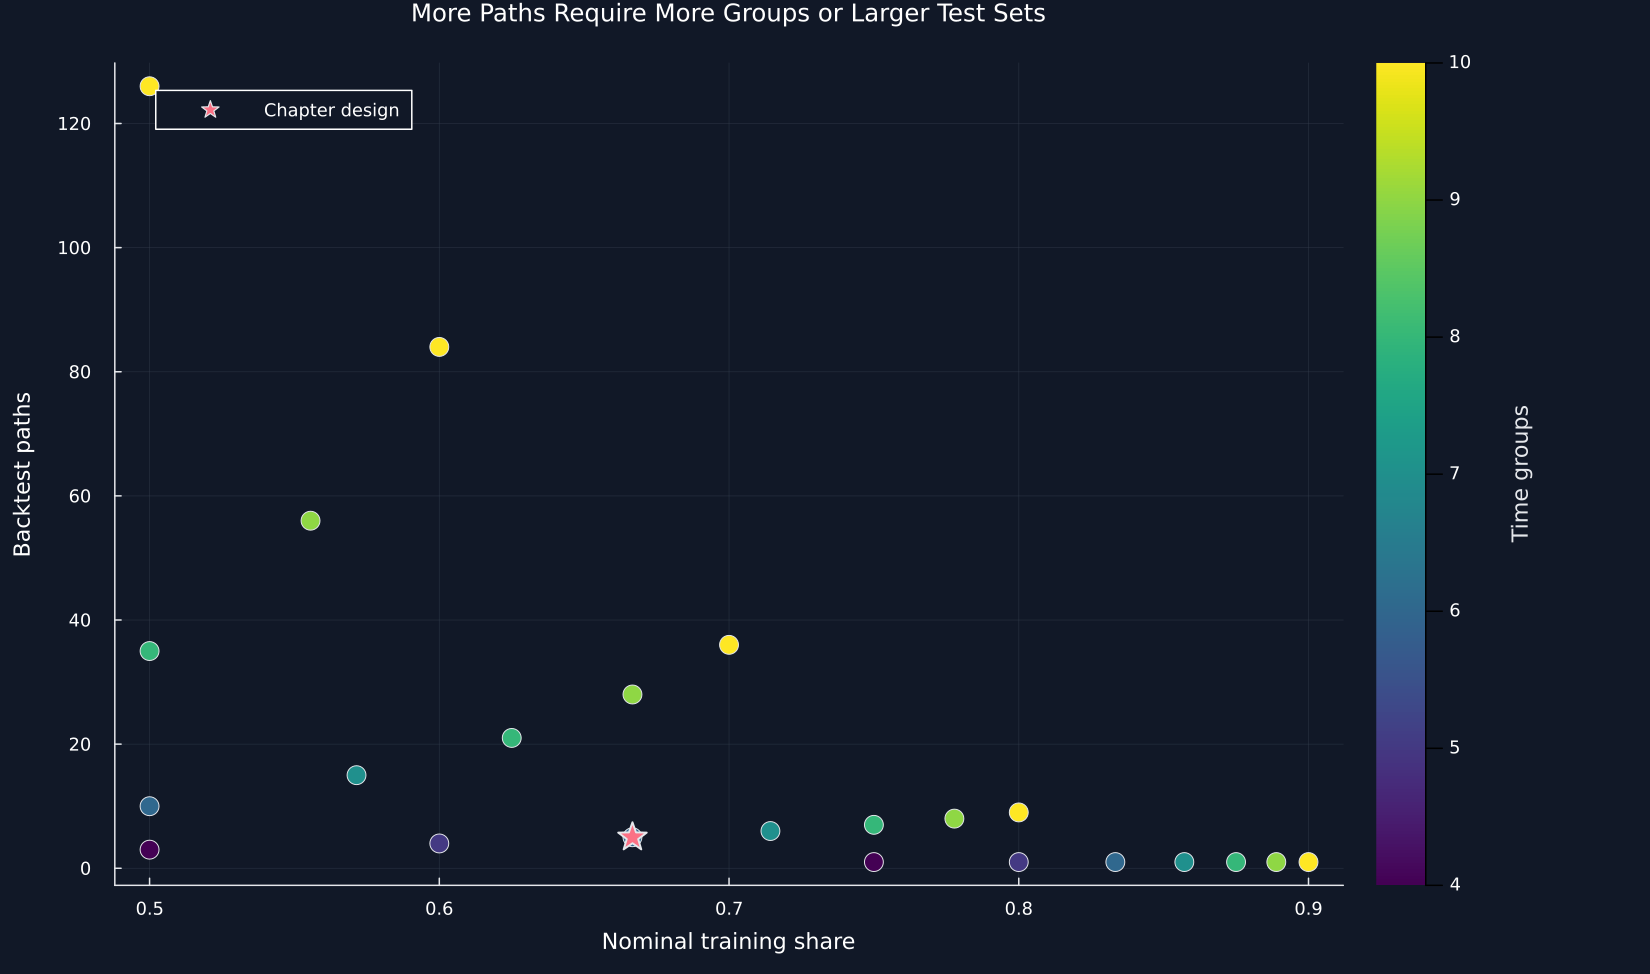

In [5]:
selected = only(eachrow(combinatorial_counts[(combinatorial_counts.Groups.==n_groups).&(combinatorial_counts[!,"Test groups"].==n_test_groups),:]))
figure = scatter(combinatorial_counts[!,"Nominal training share"],combinatorial_counts[!,"Backtest paths"];marker_z=combinatorial_counts.Groups,color=:viridis,markersize=7,markerstrokecolor=palette.text,markerstrokewidth=.5,label="",colorbar_title="Time groups",xlabel="Nominal training share",ylabel="Backtest paths",title="More Paths Require More Groups or Larger Test Sets",size=(1100,650),legend=:topleft,right_margin=18Plots.mm)
scatter!(figure,[selected["Nominal training share"]],[selected["Backtest paths"]];color=palette.rose,marker=:star5,markersize=10,label="Chapter design")
save_figure(figure,paths,"split_training_tradeoff")


## Tests

In [6]:
@assert count_observations==2951
@assert length(combinations_list)==15
@assert size(incidence)==(6,15)
@assert all(==(2),sum(incidence;dims=1))
@assert all(==(5),sum(incidence;dims=2))
@assert length(locations)==5
@assert all(length(coordinates)==6 for coordinates in values(locations))
@assert count(!iszero,assignment)==30
@assert (assignment.>0)==(incidence.>0)
@assert size(path_assignment)==(30,4)
@assert all(==(5),group_test_coverage[!,"Test appearances"])
@assert all(==(5),group_test_coverage[!,"Path segments"])
@assert size(combinatorial_counts)==(23,7)
@assert selected["Distinct splits"]==15
@assert selected["Backtest paths"]==5
@assert selected["Nominal training share"]≈2/3
@assert isfile(joinpath(paths.figures,"combinatorial_incidence.pdf"))
@assert isfile(joinpath(paths.figures,"path_assignment.pdf"))
@assert isfile(joinpath(paths.figures,"split_training_tradeoff.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"combinatorial_counts.tex"))
@assert isfile(joinpath(paths.tables,"group_test_coverage.tex"))
@assert isfile(joinpath(paths.tables,"path_assignment.tex"))
